<a href="https://colab.research.google.com/github/apkh1116/strong-kheer-191531/blob/apkh/%EC%9E%A5%EA%B7%9C%ED%98%84_4_%EA%B5%B0%EC%A7%91%EB%AA%A8%EB%8D%B8_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#[문제] 당신의 취향에 맞는 카페 음료 추천하기(교과서124p)

#[1단계] 데이터 수집하기 (caffe_menu.csv)

In [ ]:
#1-1.데이터 불러오기
import pandas as pd
df = pd.read_csv('caffe_menu.csv')
df.head()

,name,kind,volume,unit,kcal,sugars(g),fatty acids(g),caffeine(mg)
0,케냐 니에리,coffee,320,mL,4.0,0.0,0.0,204.0
1,에티오피아 게라,coffee,320,mL,4.0,0.0,0.0,204.0
2,브라질 만티게이라 BSCA,coffee,320,mL,4.0,0.0,0.0,204.0
3,과테말라 누에보 오리엔테,coffee,320,mL,4.0,0.0,0.0,204.0
4,더치 블랙 0 에티오피아 예가체프,coffee,320,mL,10.9,0.1,0.3,101.5


#[2단계] 데이터 전처리

In [ ]:
#군집 모델에 사용할 항목 선정(,)
data = df[['sugars(g)', 'caffeine(mg)']]

In [ ]:
#정규화
#정규화 값의 범위는? >> 0~1
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
dscale = scaler.fit_transform(data)

#[3단계] 모델 생성

In [ ]:
#(k-평균 군집화) 알고리즘으로 모델 생성
from sklearn.cluster import KMeans
model = KMeans(n_clusters=4)
model.fit(dscale)
df['cluster'] = model.labels_ #언더바 _ : 클래스 속에 있는 거

In [ ]:
df.head()

,name,kind,volume,unit,kcal,sugars(g),fatty acids(g),caffeine(mg),cluster
0,케냐 니에리,coffee,320,mL,4.0,0.0,0.0,204.0,3
1,에티오피아 게라,coffee,320,mL,4.0,0.0,0.0,204.0,3
2,브라질 만티게이라 BSCA,coffee,320,mL,4.0,0.0,0.0,204.0,3
3,과테말라 누에보 오리엔테,coffee,320,mL,4.0,0.0,0.0,204.0,3
4,더치 블랙 0 에티오피아 예가체프,coffee,320,mL,10.9,0.1,0.3,101.5,0


In [ ]:
#군집별 음료 확인하기
df[df['cluster']==0]['name']

,name
6,더치 오션
7,더치 썬셋
32,아포가토
67,단호박 라떼 위드 샷
68,블랙 글레이즈드 라떼
...,...
420,메가초코ICE
421,스트로베리큐브라떼
423,허니자몽블랙티
424,허니자몽블랙티


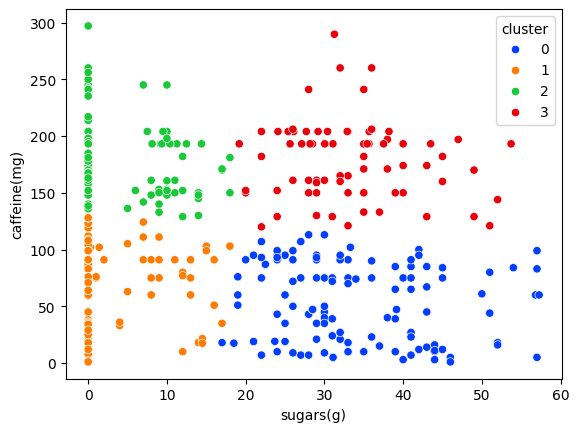

In [ ]:
# 군집 시각화를 통한 분석
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(data = df, x='sugars(g)', y='caffeine(mg)', hue='cluster', palette = 'bright')
plt.show()

In [ ]:
# 0~3 시각화를 통한 군집 분석 내용 작성하기
# 0 >>
# 1 >>
# 2 >>
# 3 >>

In [ ]:
sugar = float(input('설탕량 입력(0~50) : '))
caffeine = float(input('설탕량 입력(0~300) : '))
#데이터 형태 변경
userdata = pd.DataFrame([[sugar, caffeine]],
                        columns=['sugars(g)', 'caffeine(mg)'])
userdata

설탕량 입력(0~50) : 24
설탕량 입력(0~300) : 240


,sugars(g),caffeine(mg)\t
0,24.0,240.0


In [ ]:
#정규화
data_scale = scaler.fit_transform(userdata)

datapre = model.predict(data_scale)[0]

print('-'*45)
print(f'입력한 설탕값은 {sugar}, 카페인값은 {caffeine}')
print(f'예측한 클러스터 그룹은 {datapre}')

---------------------------------------------
입력한 설탕값은 24.0, 카페인값은 240.0
예측한 클러스터 그룹은 1


In [ ]:
#메뉴 추천
menu = df[df['cluster'] == datapre]
print(f'해당 그룹 추천 상위 10개(총 {len(menu)})')
display = ['name', 'kind', 'sugars(g)', 'caffeine(mg)']
print(menu[display].head(10))

해당 그룹 추천 상위 10개(총 143)
                  name    kind  sugars(g)  caffeine(mg)
4   더치 블랙 0 에티오피아 예가체프  coffee        0.1         101.5
5         더치 블랙 0 케냐AA  coffee        0.1         101.5
10               에스프레소  coffee        0.0         102.0
11          에스프레소 마끼아또  coffee        0.3         102.0
12           에스프레소 콘파냐  coffee        1.4         102.0
34           커스터드 플랫라떼  coffee        0.0         112.0
35        커스터드 크림샷 ICE  coffee        0.0          87.0
37         헤이즐넛 라떼 ICE  coffee        0.0         112.0
38             헤이즐넛 라떼  coffee        0.0         112.0
42          아몬드 비엔나 커피  coffee        0.0          87.0


In [ ]:
menu.head()

,name,kind,volume,unit,kcal,sugars(g),fatty acids(g),caffeine(mg),cluster
4,더치 블랙 0 에티오피아 예가체프,coffee,320,mL,10.9,0.1,0.3,101.5,1
5,더치 블랙 0 케냐AA,coffee,320,mL,10.9,0.1,0.3,101.5,1
10,에스프레소,coffee,30,mL,5.0,0.0,0.1,102.0,1
11,에스프레소 마끼아또,coffee,35,mL,8.5,0.3,0.2,102.0,1
12,에스프레소 콘파냐,coffee,40,mL,19.7,1.4,3.3,102.0,1
